In [25]:
import pandas as pd
import numpy as np
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv(r"C:\Users\HP\Downloads\student_pass_logistic_regression.csv")

In [4]:
df.head()

,Student_ID,Hours_Studied,Attendance,Previous_Score,Sleep_Hours,Assignments_Completed,Passed
0,1,2.1,61,48,5.8,5,0
1,2,5.4,82,71,7.2,8,1
2,3,3.2,68,55,6.1,6,0
3,4,6.7,91,84,7.5,9,1
4,5,4.8,76,69,6.8,8,1


In [5]:
df.shape

(150, 7)

In [6]:
df.info

<bound method DataFrame.info of      Student_ID  Hours_Studied  Attendance  Previous_Score  Sleep_Hours  \
0             1            2.1          61              48          5.8   
1             2            5.4          82              71          7.2   
2             3            3.2          68              55          6.1   
3             4            6.7          91              84          7.5   
4             5            4.8          76              69          6.8   
..          ...            ...         ...             ...          ...   
145         146            4.7          74              62          6.5   
146         147            3.5          67              51          5.9   
147         148            6.2          85              76          7.4   
148         149            5.0          79              68          6.9   
149         150            2.3          58              45          5.4   

     Assignments_Completed  Passed  
0                        5    

In [12]:
df.isnull().sum()

Student_ID               0
Hours_Studied            0
Attendance               0
Previous_Score           0
Sleep_Hours              0
Assignments_Completed    0
Passed                   0
dtype: int64

In [27]:
X = df.drop(["Student_ID", "Passed"], axis=1)
y = df["Passed"]

In [28]:
X

,Hours_Studied,Attendance,Previous_Score,Sleep_Hours,Assignments_Completed
0,2.1,61,48,5.8,5
1,5.4,82,71,7.2,8
2,3.2,68,55,6.1,6
3,6.7,91,84,7.5,9
4,4.8,76,69,6.8,8
...,...,...,...,...,...
145,4.7,74,62,6.5,7
146,3.5,67,51,5.9,5
147,6.2,85,76,7.4,9
148,5.0,79,68,6.9,8


In [29]:
y

0      0
1      1
2      0
3      1
4      1
      ..
145    1
146    0
147    1
148    1
149    0
Name: Passed, Length: 150, dtype: int64

In [19]:
from sklearn.model_selection import train_test_split

In [20]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)

In [21]:
from sklearn.linear_model import LogisticRegression

In [23]:
model = LogisticRegression()

In [26]:
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [33]:
y_pred = model.predict(X_test)

In [34]:
from sklearn.metrics import accuracy_score

In [36]:
accuracy_score(y_test, y_pred)

0.9666666666666667

In [37]:
from sklearn.metrics import  confusion_matrix

In [38]:
confusion_matrix(y_test,y_pred)

array([[15,  0],
       [ 1, 14]])

In [40]:
cm = confusion_matrix(y_test,y_pred)

<Axes: >

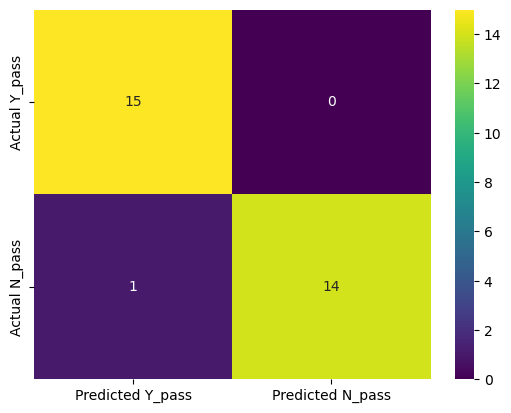

In [41]:
sns.heatmap(cm ,annot = True, cmap="viridis",  # Sets the color theme
    xticklabels=["Predicted Y_pass", "Predicted N_pass"],
    yticklabels=["Actual Y_pass", "Actual N_pass"])